In [1]:
print("Kernel is working!")

Kernel is working!


# 01 — Data Exploration
Explore the multi-sensor dataset (RGB + Thermal image pairs with annotations).

This notebook:
- Loads and visualizes RGB/Thermal image pairs
- Examines COCO-format annotations
- Analyzes class distribution
- Shows aligned image pairs with bounding boxes

In [2]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import cv2
import json
from collections import Counter
import seaborn as sns

# Project imports
from src.utils import create_sample_data, load_image, visualize_detections
from src.dataset import MultiModalDataset

%matplotlib inline
plt.rcParams['figure.figsize'] = (14, 6)

C:\Users\shiva\AppData\Local\Programs\Python\Python39\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Generate Sample Data (if no real dataset available)

In [3]:
# Use real LLVIP dataset (already processed)
DATA_DIR = os.path.join('..', 'data', 'llvip_processed')

if not os.path.exists(os.path.join(DATA_DIR, 'annotations.json')):
    # Fallback: generate synthetic sample data
    DATA_DIR = os.path.join('..', 'data', 'sample')
    os.makedirs(DATA_DIR, exist_ok=True)
    create_sample_data(DATA_DIR, num_samples=30, img_size=(480, 640))
    print(f'Sample data created at: {DATA_DIR}')
else:
    print(f'Using LLVIP dataset at: {DATA_DIR}')

Using LLVIP dataset at: ..\data\llvip_processed


## 2. Load and Examine Annotations

In [4]:
# Load COCO-format annotations
with open(os.path.join(DATA_DIR, 'annotations.json'), 'r') as f:
    coco_data = json.load(f)

print(f"Number of images: {len(coco_data['images'])}")
print(f"Number of annotations: {len(coco_data['annotations'])}")
print(f"Categories: {coco_data['categories']}")

# Class distribution
class_counts = Counter(ann['category_id'] for ann in coco_data['annotations'])
cat_names = {cat['id']: cat['name'] for cat in coco_data['categories']}

print(f"\nClass Distribution:")
for cls_id, count in sorted(class_counts.items()):
    print(f"  {cat_names.get(cls_id, cls_id)}: {count}")

Number of images: 15488


Number of annotations: 42437
Categories: [{'id': 0, 'name': 'person'}]

Class Distribution:
  person: 42437


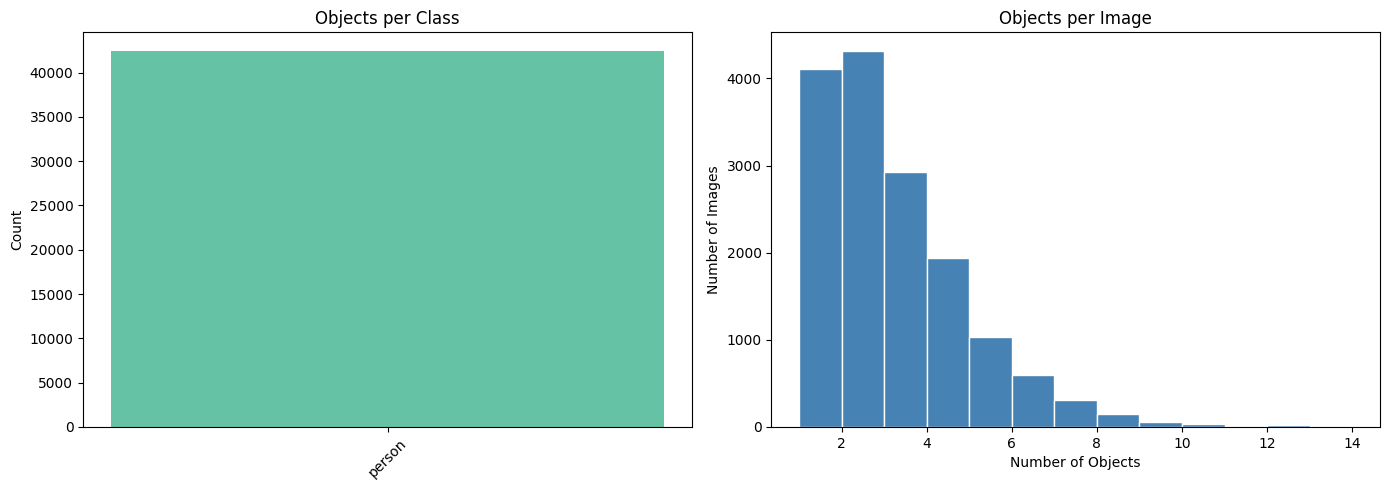

In [5]:
# Visualize class distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart
names = [cat_names.get(k, str(k)) for k in sorted(class_counts.keys())]
counts = [class_counts[k] for k in sorted(class_counts.keys())]

axes[0].bar(names, counts, color=sns.color_palette('Set2', len(names)))
axes[0].set_title('Objects per Class')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=45)

# Objects per image histogram
objs_per_img = Counter(ann['image_id'] for ann in coco_data['annotations'])
axes[1].hist(objs_per_img.values(), bins=range(1, max(objs_per_img.values())+2), 
             color='steelblue', edgecolor='white')
axes[1].set_title('Objects per Image')
axes[1].set_xlabel('Number of Objects')
axes[1].set_ylabel('Number of Images')

plt.tight_layout()
plt.show()

## 3. Visualize RGB + Thermal Image Pairs

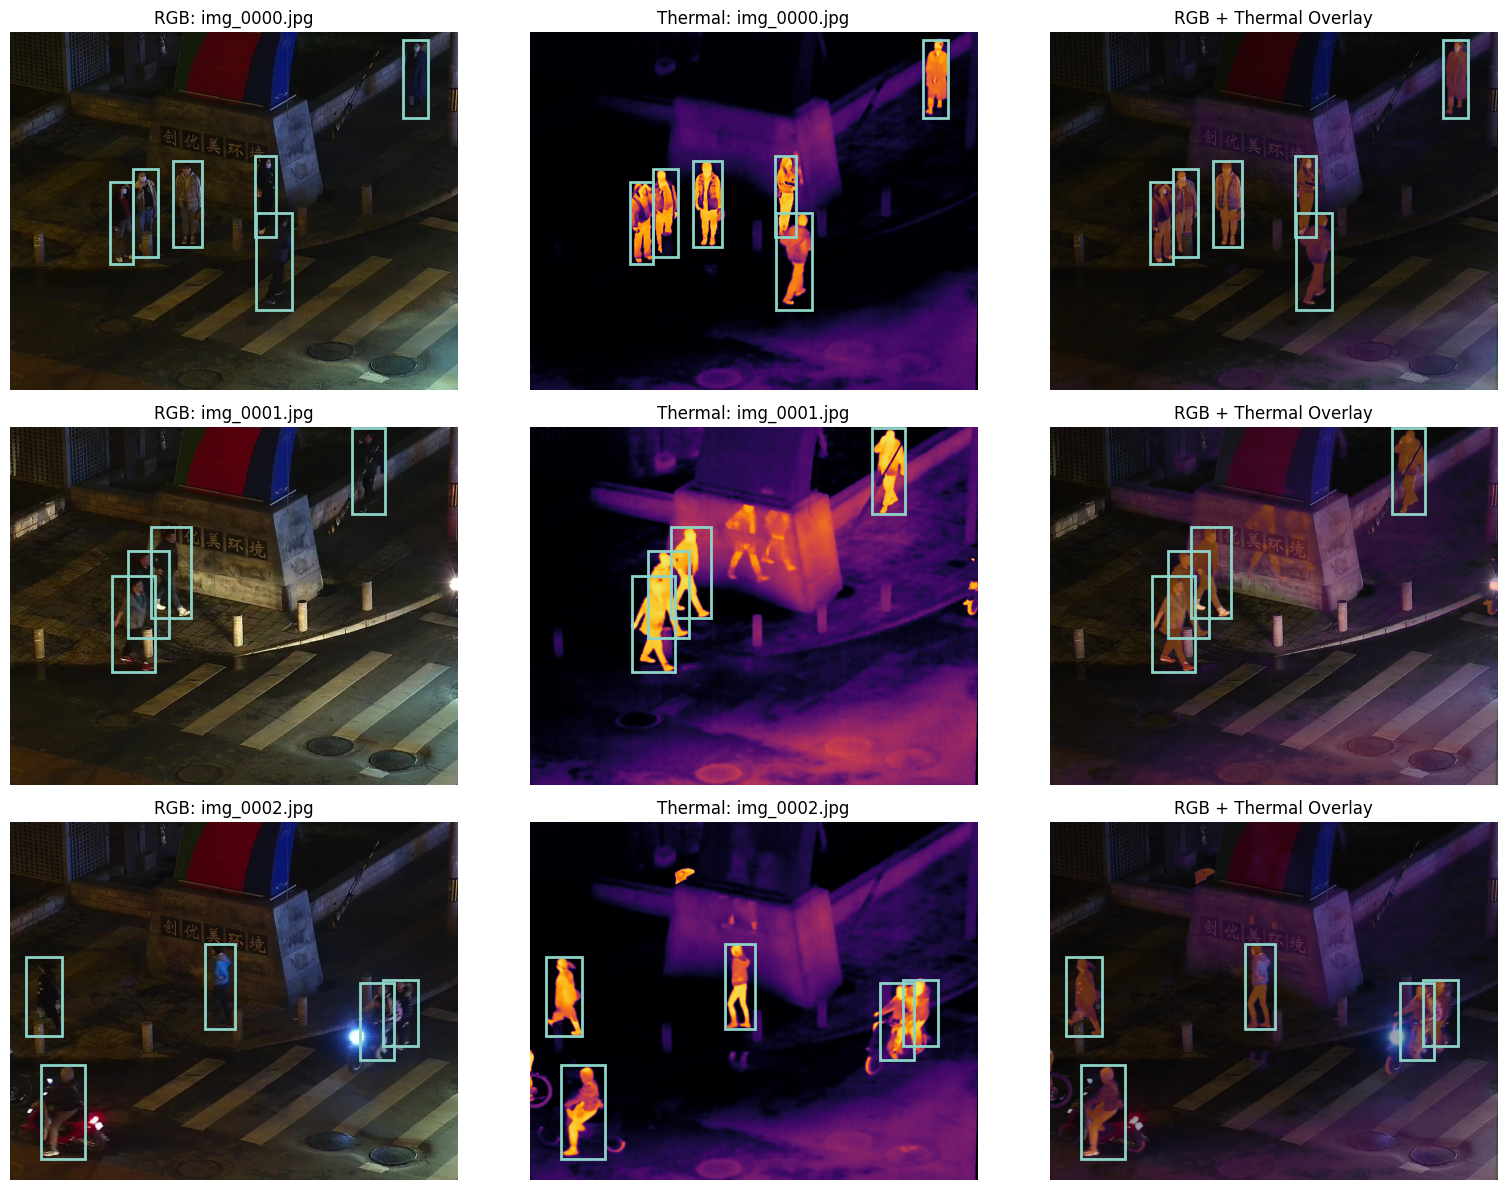

In [6]:
# Load and display some image pairs
rgb_dir = os.path.join(DATA_DIR, 'rgb')
thermal_dir = os.path.join(DATA_DIR, 'thermal')

fig, axes = plt.subplots(3, 3, figsize=(16, 12))

for i in range(3):
    img_info = coco_data['images'][i]
    fname = img_info['file_name']
    
    # Load images
    rgb = cv2.imread(os.path.join(rgb_dir, fname))
    rgb = cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB) if rgb is not None else np.zeros((480, 640, 3), dtype=np.uint8)
    
    thermal = cv2.imread(os.path.join(thermal_dir, fname), cv2.IMREAD_GRAYSCALE)
    if thermal is None:
        thermal = np.zeros((480, 640), dtype=np.uint8)
    
    # RGB
    axes[i, 0].imshow(rgb)
    axes[i, 0].set_title(f'RGB: {fname}')
    axes[i, 0].axis('off')
    
    # Thermal
    axes[i, 1].imshow(thermal, cmap='inferno')
    axes[i, 1].set_title(f'Thermal: {fname}')
    axes[i, 1].axis('off')
    
    # Overlay
    thermal_color = cv2.applyColorMap(thermal, cv2.COLORMAP_INFERNO)
    thermal_color = cv2.cvtColor(thermal_color, cv2.COLOR_BGR2RGB)
    thermal_resized = cv2.resize(thermal_color, (rgb.shape[1], rgb.shape[0]))
    overlay = cv2.addWeighted(rgb, 0.6, thermal_resized, 0.4, 0)
    axes[i, 2].imshow(overlay)
    axes[i, 2].set_title('RGB + Thermal Overlay')
    axes[i, 2].axis('off')
    
    # Draw bounding boxes
    img_anns = [a for a in coco_data['annotations'] if a['image_id'] == img_info['id']]
    colors = plt.cm.Set3(np.linspace(0, 1, 10))
    for ann in img_anns:
        x, y, w, h = ann['bbox']
        color = colors[ann['category_id'] % len(colors)]
        for ax in axes[i]:
            rect = patches.Rectangle((x, y), w, h, linewidth=2, 
                                     edgecolor=color, facecolor='none')
            ax.add_patch(rect)

plt.tight_layout()
plt.show()

## 4. Bounding Box Size Analysis

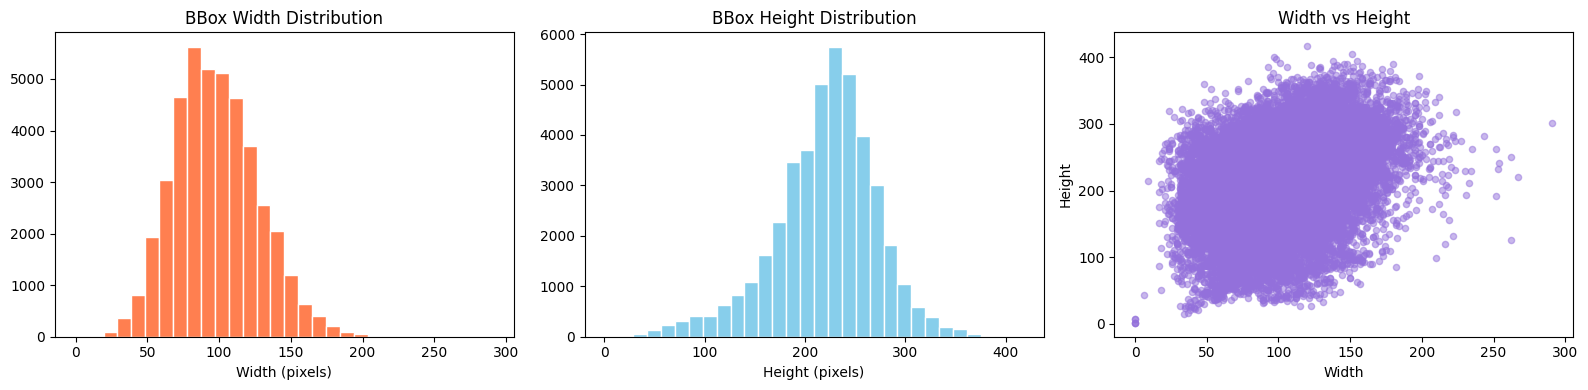

BBox stats:
  Width  — mean: 98.0, median: 96.0
  Height — mean: 220.2, median: 225.0
  Area   — mean: 22066, median: 20995


In [7]:
# Analyze bounding box sizes
widths = [ann['bbox'][2] for ann in coco_data['annotations']]
heights = [ann['bbox'][3] for ann in coco_data['annotations']]
areas = [ann['area'] for ann in coco_data['annotations']]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(widths, bins=30, color='coral', edgecolor='white')
axes[0].set_title('BBox Width Distribution')
axes[0].set_xlabel('Width (pixels)')

axes[1].hist(heights, bins=30, color='skyblue', edgecolor='white')
axes[1].set_title('BBox Height Distribution')
axes[1].set_xlabel('Height (pixels)')

axes[2].scatter(widths, heights, alpha=0.5, s=20, c='mediumpurple')
axes[2].set_title('Width vs Height')
axes[2].set_xlabel('Width')
axes[2].set_ylabel('Height')

plt.tight_layout()
plt.show()

print(f"BBox stats:")
print(f"  Width  — mean: {np.mean(widths):.1f}, median: {np.median(widths):.1f}")
print(f"  Height — mean: {np.mean(heights):.1f}, median: {np.median(heights):.1f}")
print(f"  Area   — mean: {np.mean(areas):.0f}, median: {np.median(areas):.0f}")

## 5. Test Dataset Class

In [8]:
# Test the MultiModalDataset class
dataset = MultiModalDataset(
    root_dir=DATA_DIR,
    annotation_file=os.path.join(DATA_DIR, 'annotations.json'),
    img_size=(640, 640),
    augment=False
)

print(f"Dataset size: {len(dataset)}")
print(f"Number of classes: {dataset.num_classes}")
print(f"Categories: {dataset.categories}")

# Get a sample
sample = dataset[0]
print(f"\nSample keys: {sample.keys()}")
print(f"RGB shape: {sample['rgb'].shape}")
print(f"Thermal shape: {sample['thermal'].shape}")
print(f"Boxes shape: {sample['target']['boxes'].shape}")
print(f"Labels: {sample['target']['labels']}")

Dataset size: 15488
Number of classes: 1
Categories: {0: 'person'}

Sample keys: dict_keys(['rgb', 'thermal', 'target', 'image_id', 'file_name'])
RGB shape: torch.Size([3, 640, 640])
Thermal shape: torch.Size([3, 640, 640])
Boxes shape: torch.Size([6, 4])
Labels: tensor([0, 0, 0, 0, 0, 0])
